# From three circuit axioms to the internet and a qubit, on one oscilloscope
### A checkable circuit rulebook · safe voltages and currents · 7 gates · 7 OSI layers · a qubit on the scope · MATLAB check

**In plain words.** A physics major doesn't memorise a thousand circuit rules. They learn three
axioms and derive the rest:

1. **KCL:** charge is conserved, so the currents leaving any node add to zero.
2. **KVL:** voltage is a potential, so the drops around any loop add to zero.
3. **Element laws:** $v = Ri$, $i = C\,dv/dt$, $v = L\,di/dt$ (plus $M\,di/dt$ for coupled coils).

Here a small symbolic solver (`dgs.circuit_rules`) applies those axioms to every node at once and
**derives 52 named rules**: series and parallel, dividers, filters, Thevenin, op-amps, RLC
resonance, transformers and so on. Each rule is checked symbolically, not memorised. Then:
- the same machinery answers "**is this circuit safe to touch and to build?**";
- the voltages become **logic gates**;
- the gates become the **7 OSI layers** of a real network frame, whose bits are voltages on a scope
  (`dgs.gates_to_internet`);
- the same scope watches a **one-qubit experiment** (`dgs.qubit_scope`): drive volts in, readout
  volts out, one knob swept at a time (a 1-D sweep).

MATLAB re-checks the key numbers independently at the end.

Figures use the Okabe-Ito palette, curves differ by line style too, and each figure has a printed
text description.

In [1]:
import sys, pathlib, math, shutil, subprocess
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import numpy as np, sympy as sp, matplotlib.pyplot as plt
from dgs import circuit_rules as cr, gates_to_internet as gi, qubit_scope as qs
from dgs.circuit_rules import Circuit, s, t
from dgs.scope_bench import Scope
from dgs.spice import rlc_step_response
sp.init_printing()
OI = ["#E69F00", "#56B4E9", "#009E73", "#D55E00", "#CC79A7", "#0072B2", "#000000"]
plt.rcParams["axes.prop_cycle"] = plt.cycler(color=OI)

## 1. The axioms as one matrix equation

In the Laplace domain $d/dt \to s$, so a capacitor is an admittance $sC$ and an inductor an impedance
$sL$. Writing KCL at every node, with the element laws substituted in, gives one linear system
$A\,x = b$ (Modified Nodal Analysis). The unknowns are the node voltages plus the currents in sources,
inductors and op-amp outputs. Solving it *is* applying the three axioms. Example: an RC low-pass
driven by a step $V_0/s$.

In [2]:
V0, R, C = sp.symbols("V_0 R C", positive=True)
rc = Circuit("RC").V("Vs", "in", "0", V0/s).R("R1", "in", "out", R).C("C1", "out", "0", C)
sol = rc.solve()
print("V_out(s) ="); display(sol.V("out"))
print("v_out(t) ="); display(cr.to_time(sol.V("out")))
print("KCL residual at every node:", cr.kcl_residuals(rc, sol))
print("Tellegen sum of v*i over all branches:", cr.tellegen_sum(sol))

V_out(s) =


v_out(t) =


KCL residual at every node: {'in': 0, 'out': 0}
Tellegen sum of v*i over all branches: 0


## 2. The rulebook: 52 rules, each derived from the axioms

Every rule below has a `check()` that builds a small circuit, solves it with the axioms, and
confirms the formula symbolically. A ✓ means SymPy proved it for all positive part values (or, for
KCL, Tellegen and reciprocity, for a messy network with exact rational values and symbolic $s$).
`test_checks_can_fail` in the test file makes sure a wrong rule, such as "series capacitors add", is
caught.

In [3]:
results = cr.verify_all()
for cat in cr.CATEGORIES:
    print(f"--- {cat}")
    for r in [r for r in cr.RULES if r.category == cat]:
        ok = dict((n, o) for n, _, o in results)[r.name]
        print(f"  {'✓' if ok else '✗'} {r.name:26s} {r.formula}")
print(f"\n{sum(o for *_, o in results)} / {len(results)} rules derived from KCL + KVL + element laws")

--- axiom
  ✓ KCL                        sum_k i_k = 0
  ✓ KVL                        V = I (R + sL + 1/(sC))
  ✓ Ohm's law                  i = v / R
  ✓ Capacitor law              Z_C = 1/(sC)
  ✓ Inductor law               Z_L = sL
  ✓ Coupled inductors          v2 = s M i1,  M = k sqrt(L1 L2)
--- combination
  ✓ Series resistors           R = R1 + R2
  ✓ Parallel resistors         R = R1 R2 / (R1 + R2)
  ✓ Series inductors           L = L1 + L2
  ✓ Parallel inductors         L = L1 L2 / (L1 + L2)
  ✓ Series capacitors          C = C1 C2 / (C1 + C2)
  ✓ Parallel capacitors        C = C1 + C2
--- divider
  ✓ Voltage divider            v_out = V R2 / (R1 + R2)
  ✓ Current divider            i_1 = I R2 / (R1 + R2)
--- filter
  ✓ RC low-pass                H(s) = 1 / (1 + sRC)
  ✓ RC high-pass               H(s) = sRC / (1 + sRC)
  ✓ RL low-pass                H(s) = R / (R + sL)
--- theorem
  ✓ Thevenin                   v_load = V_oc Z_L / (Z_L + Z_th)
  ✓ Norton                     I

## 3. "Derive any circuit": one the rulebook doesn't contain

The rules are shortcuts; the axioms do the real work, so the solver handles circuits that have no
named rule. Take a unity-gain **Sallen-Key low-pass**, a standard active filter: $R_1$, $R_2$ in
series into the op-amp's + input, $C_1$ from their midpoint back to the output, $C_2$ from the +
input to ground, and the op-amp wired as a buffer. Textbook result (quoted from memory):
$\omega_0 = 1/\sqrt{R_1R_2C_1C_2}$, $Q = \sqrt{R_1R_2C_1C_2}/\big(C_2(R_1+R_2)\big)$.

H(s) =


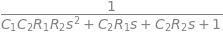

omega0 =


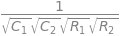

Q =


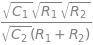

matches textbook omega0: True   Q: True
with 10k, 10k, 22 nF, 10 nF: f0 = 1073.0 Hz, Q = 0.742


In [4]:
R1, R2, C1, C2, Vin = sp.symbols("R1 R2 C1 C2 V_in", positive=True)
sk = Circuit("Sallen-Key").V("Vs", "in", "0", Vin).R("R1", "in", "m", R1).R("R2", "m", "p", R2)
sk.C("C1", "m", "out", C1).C("C2", "p", "0", C2).opamp("U1", "p", "out", "out")
H = sp.simplify(sk.solve().V("out")/Vin)
print("H(s) ="); display(H)
p = cr._char_poly(H)
w0 = sp.sqrt(p.coeff_monomial(1)); Q = sp.simplify(w0/p.coeff_monomial(s))
print("omega0 ="); display(sp.simplify(w0)); print("Q ="); display(Q)
print("matches textbook omega0:", cr._same(w0, 1/sp.sqrt(R1*R2*C1*C2)),
      "  Q:", cr._same(Q, sp.sqrt(R1*R2*C1*C2)/(C2*(R1 + R2))))
vals = {R1: 10e3, R2: 10e3, C1: 22e-9, C2: 10e-9}
print(f"with 10k, 10k, 22 nF, 10 nF: f0 = {float(w0.subs(vals))/(2*math.pi):.1f} Hz, Q = {float(Q.subs(vals)):.3f}")

### Cross-check against a time-domain simulation

The rulebook's series-RLC step response (inverse Laplace transform of the solver's answer) should
match `dgs.spice.rlc_step_response`, which integrates the ODE with RK4 and knows nothing about Laplace
transforms. Three resistances give underdamped, critically damped and overdamped responses.

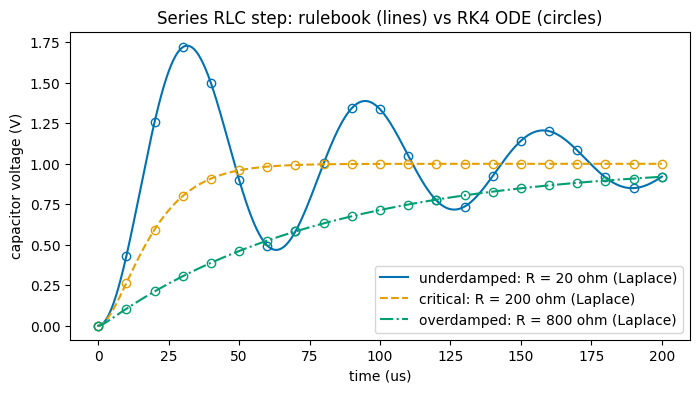

largest difference between the two methods: 2.06e-09 V
Text description: capacitor voltage after a 1 V step for L = 1 mH, C = 100 nF. The solid blue underdamped curve (20 ohm) overshoots to about 1.85 V and rings at about 16 kHz; the dashed orange critically damped curve (R = 200 ohm) rises to 1 V fastest without overshoot; the dash-dot green overdamped curve (800 ohm) creeps up slowly. Open circles from the independent RK4 integration lie on each line.


In [5]:
Lv, Cv = 1e-3, 100e-9
Rcrit = 2*math.sqrt(Lv/Cv)
tt = np.linspace(0, 200e-6, 2001)
fig, ax = plt.subplots(figsize=(8, 4))
worst = 0
for Rv, ls, c, lab in ((20, "-", OI[5], "underdamped"), (Rcrit, "--", OI[0], "critical"), (4*Rcrit, "-.", OI[2], "overdamped")):
    ckt = Circuit().V("Vs", "in", "0", 1/s).R("R", "in", "a", Rv).L("L", "a", "b", Lv).C("C", "b", "0", Cv)
    vt = cr.to_time(ckt.solve(simplify=False).V("b"))
    f = sp.lambdify(t, vt, "numpy")
    v_rule = np.real(f(tt[1:]))
    v_ode, _ = rlc_step_response(Rv, Lv, Cv, tt)
    worst = max(worst, np.max(np.abs(v_rule - v_ode[1:])))
    ax.plot(tt*1e6, np.r_[0, v_rule], ls, color=c, label=f"{lab}: R = {Rv:.0f} ohm (Laplace)")
    ax.plot(tt[::100]*1e6, v_ode[::100], "o", mfc="none", color=c)
ax.set_xlabel("time (us)"); ax.set_ylabel("capacitor voltage (V)"); ax.legend(); ax.set_title("Series RLC step: rulebook (lines) vs RK4 ODE (circles)")
plt.show()
print(f"largest difference between the two methods: {worst:.2e} V")
print("Text description: capacitor voltage after a 1 V step for L = 1 mH, C = 100 nF. The solid blue underdamped curve "
      "(20 ohm) overshoots to about 1.85 V and rings at about 16 kHz; the dashed orange critically damped curve "
      f"(R = {Rcrit:.0f} ohm) rises to 1 V fastest without overshoot; the dash-dot green overdamped curve ({4*Rcrit:.0f} ohm) "
      "creeps up slowly. Open circles from the independent RK4 integration lie on each line.")

## 4. Safe voltages, currents, resistances and capacitances

The rules tell you what a circuit *does*; safety asks whether it hurts a **person** or a **part**.

**People.** What hurts is the current through the body, $I = V/Z_\text{body}$. Body impedance falls as
voltage rises because the skin breaks down: about 3 kΩ hand to hand at 25 V, under 1 kΩ near 1 kV.
That is why "extra-low voltage" stops around 50 V AC / 120 V DC (dry). The limits and current bands
below are teaching defaults **written from memory**, loosely after IEC 60479-1 and IEC 61140; they are
not quotes from the standards and not a safety sign-off.

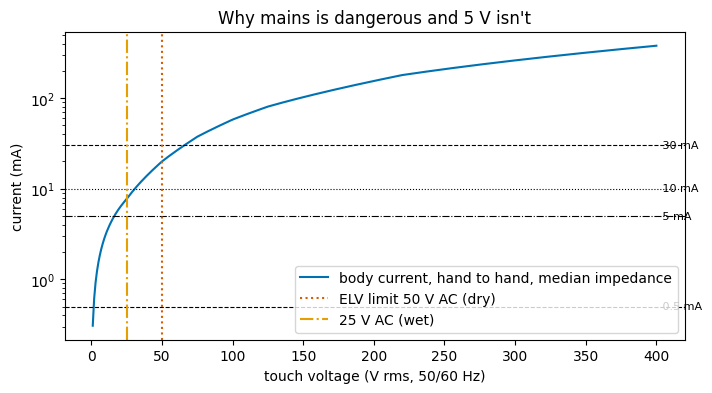

   5 V AC: body   3250 ohm ->    1.5 mA  (perceptible, startling, usually harmless)
  12 V AC: body   3250 ohm ->    3.7 mA  (perceptible, startling, usually harmless)
  24 V AC: body   3250 ohm ->    7.4 mA  (painful; near the let-go limit)
  48 V AC: body   2560 ohm ->   18.8 mA  (cannot let go; muscle contraction, breathing difficulty)
 120 V AC: body   1585 ohm ->   75.7 mA  (ventricular fibrillation possible (depends on duration and path): DANGEROUS)
 230 V AC: body   1216 ohm ->  189.2 mA  (ventricular fibrillation possible (depends on duration and path): DANGEROUS)
Text description: body current (log axis) against touch voltage. The solid blue curve rises faster than linearly because body impedance falls with voltage: about 1.5 mA at 5 V, 19 mA at 48 V, 76 mA at 120 V, 190 mA at 230 V. Thin black horizontal lines at 0.5, 5, 10 and 30 mA separate the bands (perception, startle, let-go, fibrillation risk). The dotted vermillion vertical line marks the 50 V AC extra-low-voltage lim

In [6]:
Vt = np.linspace(1, 400, 400)
I_ac = np.array([cr.shock_assessment(v)["I_mA"] for v in Vt])
fig, ax = plt.subplots(figsize=(8, 4))
ax.semilogy(Vt, I_ac, "-", color=OI[5], label="body current, hand to hand, median impedance")
for (lim, lab), ls in zip(cr.AC_BANDS[:-1], ("--", "-.", ":", "--")):
    ax.axhline(lim, ls=ls, color=OI[6], lw=0.8); ax.text(402, lim, f" {lim:g} mA", va="center", fontsize=8)
ax.axvline(cr.SAFETY["elv_ac_rms"], ls=":", color=OI[3], label="ELV limit 50 V AC (dry)")
ax.axvline(cr.SAFETY["elv_ac_rms_wet"], ls="-.", color=OI[0], label="25 V AC (wet)")
ax.set_xlabel("touch voltage (V rms, 50/60 Hz)"); ax.set_ylabel("current (mA)"); ax.legend(loc="lower right"); ax.set_title("Why mains is dangerous and 5 V isn't")
plt.show()
for v in (5, 12, 24, 48, 120, 230):
    a = cr.shock_assessment(v)
    print(f"{v:4d} V AC: body {a['R_body']:6.0f} ohm -> {a['I_mA']:6.1f} mA  ({a['band']})")
print("Text description: body current (log axis) against touch voltage. The solid blue curve rises faster than "
      "linearly because body impedance falls with voltage: about 1.5 mA at 5 V, 19 mA at 48 V, 76 mA at 120 V, "
      "190 mA at 230 V. Thin black horizontal lines at 0.5, 5, 10 and 30 mA separate the bands (perception, startle, "
      "let-go, fibrillation risk). The dotted vermillion vertical line marks the 50 V AC extra-low-voltage limit and "
      "the dash-dot orange line the 25 V wet limit.")

The 48 V row shows the limits of this model. 48 V AC sits just inside the dry ELV limit, yet the
median-impedance estimate lands in the "can't let go" band. The real standards also weigh contact
time, contact area, the current's path and the population spread, which this simplified table
ignores. Read the table as "keep exposed voltages low and treat anything above about 25 V AC with
respect", not as permission.

**Parts.** `safety_check` solves the DC operating point and checks each component:
- resistor power against a derated 1/4 W;
- capacitor voltage against 80 % of its rating, and its stored energy;
- the voltage an inductor kicks back when a switch opens.

Example: a 24 V relay coil (100 Ω, 10 mH) switched by a transistor through a 100 Ω current-limit
resistor.

In [7]:
relay = Circuit("relay").V("Vs", "vcc", "0", 24).R("Rlim", "vcc", "a", 100).L("Lcoil", "a", "b", 10e-3).R("Rcoil", "b", "0", 100)
for f in cr.safety_check(relay, ratings={"Rlim": 2.0, "Lcoil": 60}, switch_off_time=1e-6):
    print(f"[{f['status']:4s}] {f['part']:6s} {f['quantity']:26s} {f['note']}")
print(f"\nflyback diode clamps the coil to about one diode drop (~0.7 V) above the rail; the 0.12 A then decays with "
      f"tau = L/R_coil = {10e-3/100*1e6:.0f} us")
print(f"bleeder for a 470 uF, 400 V bus with 47 kOhm: {cr.bleeder_time(470e-6, 47e3, 400, 60):.1f} s to fall below 60 V "
      f"(RC ln(400/60)); stored energy {0.5*470e-6*400**2:.1f} J")

[OK  ] Vs     source voltage (V)         extra-low voltage (dry)
[WARN] Rlim   power (W)                  1.44e+03 mW vs derated limit 1e+03 mW
[WARN] Lcoil  switch-off kickback (V)    L I / t_off = 1.2e+03 V for t_off = 1e-06 s; add a flyback diode or snubber
[WARN] Rcoil  power (W)                  1.44e+03 mW vs derated limit 125 mW

flyback diode clamps the coil to about one diode drop (~0.7 V) above the rail; the 0.12 A then decays with tau = L/R_coil = 100 us
bleeder for a 470 uF, 400 V bus with 47 kOhm: 41.9 s to fall below 60 V (RC ln(400/60)); stored energy 37.6 J


## 5. Voltages become the 7 basic gates

A gate's output is a voltage. The receiving gate reads it as 1 above $V_{IH}$, as 0 below $V_{IL}$,
and as undefined in between. NAND alone can build every gate, which is why a chip can be made of
one repeated cell. The delay is an RC delay: the 50 % crossing comes at $R_\text{on}C_\text{load}\ln 2$,
which is rule "50 % delay" from section 2.

In [8]:
print("gate   truth table (00 01 10 11)   NANDs needed   CMOS transistors")
for g in gi.GATES:
    tt_ = gi.truth_table(g)
    f, n = gi.nand_only(g)
    assert all(f(*b) == o for b, o in tt_)
    print(f"{g:5s}  {' '.join(str(o) for _, o in tt_):27s}  {n:12d}   {gi.CMOS_TRANSISTORS[g]:8d}")
print("\n3.3 V levels (LVTTL-compatible, from memory):", gi.LOGIC_LEVELS_3V3, " noise margins:", gi.noise_margins())
print(f"gate delay with R_on = 50 ohm, C_load = 5 pF: {gi.gate_delay(50, 5e-12)*1e12:.0f} ps  (rulebook: RC ln 2)")

gate   truth table (00 01 10 11)   NANDs needed   CMOS transistors
AND    0 0 0 1                                 2          6
OR     0 1 1 1                                 3          6
NOT    1 0                                     1          2
NAND   1 1 1 0                                 1          4
NOR    1 0 0 0                                 4          4
XOR    0 1 1 0                                 4         12
XNOR   1 0 0 1                                 5         12

3.3 V levels (LVTTL-compatible, from memory): {'VCC': 3.3, 'VOH': 2.4, 'VOL': 0.4, 'VIH': 2.0, 'VIL': 0.8}  noise margins: {'NM_H': 0.3999999999999999, 'NM_L': 0.4}
gate delay with R_on = 50 ohm, C_load = 5 pF: 173 ps  (rulebook: RC ln 2)


## 6. Gates become the 7 OSI layers

Each layer wraps the one above in its own header and hides it from the layers below. This builds a
real frame: a UTF-8 message, inside a UDP datagram (with the RFC 768/1071 checksum), inside an IPv4
packet (with its header checksum), inside an Ethernet II frame (with the CRC-32 that XOR shift
registers compute in hardware), turned into bits for the wire.

In [9]:
for L in gi.OSI_LAYERS:
    print(f"L{L['n']} {L['name']:12s} [{L['pdu']:18s}] {L['job']}\n{'':17s} e.g. {L['examples']};  physically: {L['physical']}")
fr = gi.encapsulate("Hello from layer 7")
print()
for key in ("L6", "L4", "L3", "L2"):
    print(f"{key}: {len(fr[key]):3d} bytes  {fr[key][:24].hex(' ')} ...")
print(f"L1: {len(fr['L1_bits'])} bits on the wire (preamble + frame)")
back = gi.decapsulate(fr["L2"])
print("\nback up the stack:", back)
bad = bytearray(fr["L2"]); bad[40] ^= 0x08
print("one bit flipped in the IP payload ->", gi.decapsulate(bytes(bad))["checks"])
print("bit-serial CRC-32 == zlib:", gi.crc32_bitwise(fr["L2"][:-4]) == int.from_bytes(fr["L2"][-4:], "little"))

L7 Application  [data              ] what the program means: a web request, a DNS query
                  e.g. HTTP, DNS, SMTP, SSH;  physically: bytes in a program's memory
L6 Presentation [data              ] how the meaning is written down: text encoding, compression, encryption
                  e.g. UTF-8, JPEG, TLS record encryption;  physically: byte transformations
L5 Session      [data              ] keeping a conversation going: open, resume, close
                  e.g. TLS sessions, RPC, NetBIOS;  physically: state in software
L4 Transport    [segment / datagram] which program on the host; reliability and ordering if wanted
                  e.g. TCP, UDP (ports);  physically: header bytes + checksum
L3 Network      [packet            ] which host, across many links; routing
                  e.g. IPv4, IPv6, ICMP;  physically: header bytes + header checksum (IPv4)
L2 Data link    [frame             ] the next hop on one shared link; MAC addresses; error detection
         

## 7. Layer 1 on the oscilloscope

10BASE-T Ethernet sends bits with **Manchester coding** (IEEE 802.3 convention, from memory: 0 is a
high-to-low transition mid-bit, 1 is low-to-high). That gives an edge in every bit, which the
receiver uses as its clock, and zero average voltage. Below, the start of our frame at 10 Mb/s with
±2.5 V levels and 5 ns edges, viewed on the simulated scope next to plain NRZ of the same bits. Then
the bits are decoded back from what the *scope* captured.

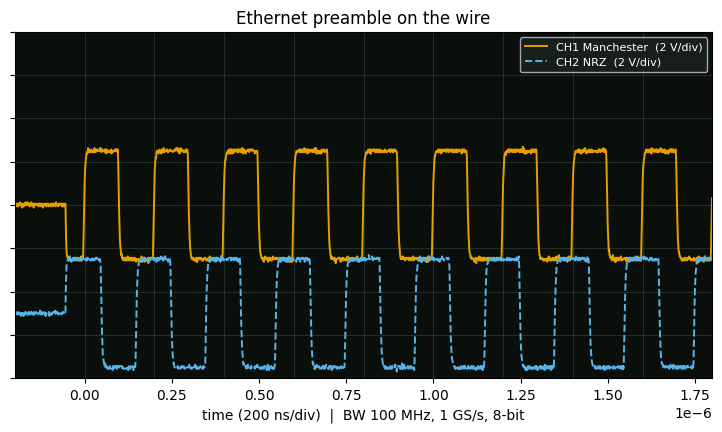

Text description: Oscilloscope screen, 10 x 8 divisions, trigger at t = 0 on CH1 (rising through 1 V). CH1 (Manchester, '-' line): 4.999 MHz, 5.38 Vpp; CH2 (NRZ, '--' line): 4.998 MHz, 5.38 Vpp. CH1 (orange, solid) is Manchester: a transition in the middle of every bit, so the preamble's alternating 1010... looks like a clean 5 MHz square wave with edges every 100 ns. CH2 (blue, dashed, drawn 2.5 divisions lower) is NRZ of the same bits: one level per bit, so the 1010 preamble is a 5 MHz square wave too, but a long run of equal bits would be a flat line with no clock edges and a DC offset.
decoded 18 bits from the scope samples; match the transmitted bits: True


In [10]:
bits = fr["L1_bits"][:64]
t0 = 2e-6
man = gi.line_waveform(bits, 10e6, "manchester", rise_time=5e-9, t0=t0)
nrz = gi.line_waveform(bits, 10e6, "nrz", rise_time=5e-9, t0=t0)
scope = Scope(bandwidth=100e6, sample_rate=1e9, bits=8, noise_vrms=0.05)
scope.connect(1, "Manchester", man, volts_per_div=2, offset=0)
scope.connect(2, "NRZ", nrz, volts_per_div=2, offset=5.0)                # offset moves the trace down 2.5 div
scope.trigger(channel=1, level=1.0, slope="rising")      # above the noise on the idle line
shot = scope.acquire(time_per_div=200e-9, pre_trigger=0.1)
fig, ax = plt.subplots(figsize=(9, 4.5))
_, desc = scope.plot(shot, ax=ax, title="Ethernet preamble on the wire")
plt.show()
print("Text description:", desc, "CH1 (orange, solid) is Manchester: a transition in the middle of every bit, so the "
      "preamble's alternating 1010... looks like a clean 5 MHz square wave with edges every 100 ns. CH2 (blue, dashed, "
      "drawn 2.5 divisions lower) is NRZ of the same bits: one level per bit, so the 1010 preamble is a 5 MHz square wave too, but a long run of equal bits would be a flat line with no clock edges and a DC offset.")
t_scope = shot["t"] + shot["trig_time"]
sampled = lambda tq: np.interp(tq, t_scope, shot["ch"][1])
k0 = max(0, int(np.ceil((t_scope[0] - t0) * 10e6)))      # first whole bit on screen
nb_ = int((t_scope[-1] - t0) * 10e6) - k0
dec = gi.manchester_decode(sampled, nb_, 10e6, t0=t0 + k0/10e6)
print(f"decoded {nb_} bits from the scope samples; match the transmitted bits: {dec == bits[k0:k0+nb_]}")

## 8. A one-qubit experiment on the same scope

A superconducting or trapped-ion qubit is driven by an AWG burst. The amplitude in volts sets the
Rabi frequency, $\Omega = \kappa A$, and the burst length sets the rotation angle. The readout
returns a voltage that is slightly higher for $|1\rangle$ and buried in noise, so each point is
averaged over many shots. "1-D" here means one knob swept at a time.
- **Rabi:** sweep the pulse length; $P_1 = (\Omega^2/W^2)\sin^2(Wt/2)$ with $W = \sqrt{\Omega^2+\Delta^2}$.
- **Ramsey:** sweep the wait between two π/2 pulses; $P_1 = \tfrac12(1 + e^{-\tau/T_2}\cos\Delta\tau)$.

Both formulas are checked against direct integration of the Schrödinger equation (`tests/test_qubit_scope.py`,
agreement about $10^{-16}$). κ, the readout levels and the noise are illustrative, not from a
particular device.

Omega/2pi = 2.00 MHz  ->  pi pulse 250 ns


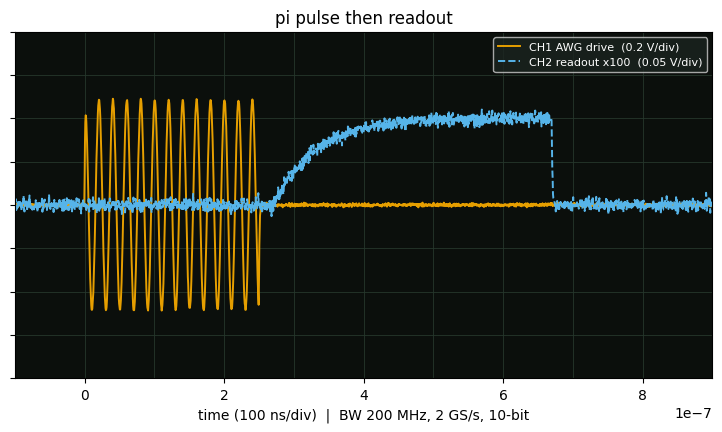

Text description: Oscilloscope screen, 10 x 8 divisions, trigger at t = 0 on CH1 (rising through 0.1 V). CH1 (AWG drive, '-' line): 50.044 MHz, 0.978 Vpp; CH2 (readout x100, '--' line): 1.478 MHz, 0.123 Vpp. CH1 (orange, solid) is a 250 ns, 0.5 V, 50 MHz burst: the pi pulse. CH2 (blue, dashed) is the readout after a x100 amplifier: it rings up with a 60 ns time constant to about 0.1 V because the qubit is now in |1>; for |0> it would stay at 0 V.


In [11]:
kappa = 2*np.pi*4e6          # rad/s per volt (illustrative)
A = 0.5                       # drive amplitude, volts
Om = kappa*A
t_pi = math.pi/Om
print(f"Omega/2pi = {Om/2/np.pi/1e6:.2f} MHz  ->  pi pulse {t_pi*1e9:.0f} ns")
drive = qs.drive_voltage(A, t_pi, 50e6, t_start=1e-6)
ro = qs.readout_trace(1e-3*qs.rabi_probability(t_pi, Om)*100, t_start=1e-6 + t_pi + 20e-9, t_len=400e-9, tau_ring=60e-9)
sc = Scope(bandwidth=200e6, sample_rate=2e9, bits=10, noise_vrms=0.004)
sc.connect(1, "AWG drive", drive, volts_per_div=0.2)
sc.connect(2, "readout x100", lambda tt_: ro(tt_) - 0.0, volts_per_div=0.05, offset=0)
sc.trigger(channel=1, level=0.1, slope="rising")
shot = sc.acquire(time_per_div=100e-9, pre_trigger=0.1)
fig, ax = plt.subplots(figsize=(9, 4.5))
_, desc = sc.plot(shot, ax=ax, title="pi pulse then readout")
plt.show()
print("Text description:", desc, f"CH1 (orange, solid) is a {t_pi*1e9:.0f} ns, 0.5 V, 50 MHz burst: the pi pulse. "
      "CH2 (blue, dashed) is the readout after a x100 amplifier: it rings up with a 60 ns time constant to about 0.1 V "
      "because the qubit is now in |1>; for |0> it would stay at 0 V.")

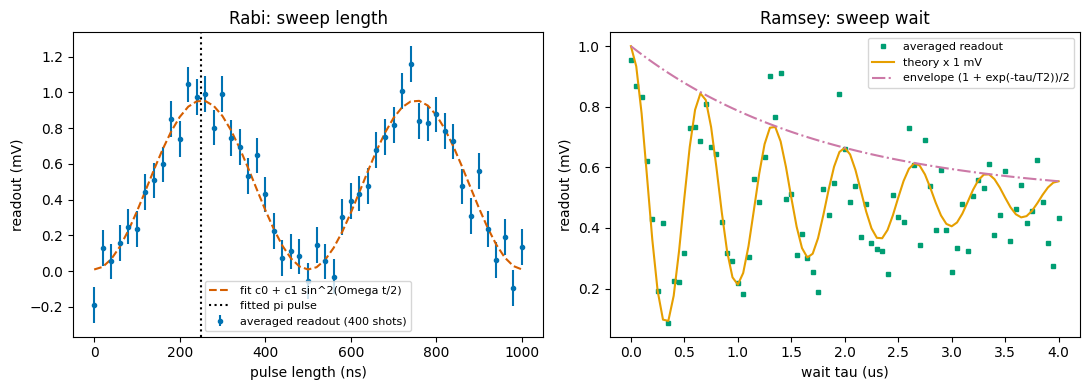

true Omega/2pi = 2.000 MHz, fitted = 1.994 MHz (0.30 % off); fitted pi pulse 250.7 ns vs true 250.0 ns
Text description: left, averaged readout voltage (blue circles with error bars) against drive length oscillates between 0 and 1 mV, completing two full cycles in 1 us; the dashed vermillion fit follows it and the dotted black line marks the fitted pi pulse at 251 ns. Right, the Ramsey fringe (green squares) oscillates at the 1.5 MHz detuning while its swing shrinks inside the dash-dot pink envelope set by T2 = 1.8 us; the solid orange theory curve passes through the points.


In [12]:
d = np.linspace(0, 1e-6, 51)
exp = qs.rabi_experiment(d, A, kappa, n_shots=400, rng=7)
Om_fit, c0, c1 = qs.fit_rabi(exp["durations"], exp["v_mean"])
taus = np.linspace(0, 4e-6, 81)
Delta, T2 = 2*np.pi*1.5e6, 1.8e-6
rng = np.random.default_rng(11)
ram = np.array([qs.single_shots(p, 400, 0, 1e-3, 2e-3, rng).mean() for p in qs.ramsey_probability(taus, Delta, T2)])
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].errorbar(d*1e9, exp["v_mean"]*1e3, yerr=exp["v_err"]*1e3, fmt="o", ms=3, color=OI[5], label="averaged readout (400 shots)")
ax[0].plot(d*1e9, (c0 + c1*np.sin(Om_fit*d/2)**2)*1e3, "--", color=OI[3], label="fit c0 + c1 sin^2(Omega t/2)")
ax[0].axvline(math.pi/Om_fit*1e9, ls=":", color=OI[6], label="fitted pi pulse")
ax[0].set_xlabel("pulse length (ns)"); ax[0].set_ylabel("readout (mV)"); ax[0].legend(fontsize=8); ax[0].set_title("Rabi: sweep length")
ax[1].plot(taus*1e6, ram*1e3, "s", ms=3, color=OI[2], label="averaged readout")
ax[1].plot(taus*1e6, qs.ramsey_probability(taus, Delta, T2), "-", color=OI[0], label="theory x 1 mV")
ax[1].plot(taus*1e6, 0.5*(1 + np.exp(-taus/T2)), "-.", color=OI[4], label="envelope (1 + exp(-tau/T2))/2")
ax[1].set_xlabel("wait tau (us)"); ax[1].set_ylabel("readout (mV)"); ax[1].legend(fontsize=8); ax[1].set_title("Ramsey: sweep wait")
plt.tight_layout(); plt.show()
print(f"true Omega/2pi = {Om/2/np.pi/1e6:.3f} MHz, fitted = {Om_fit/2/np.pi/1e6:.3f} MHz "
      f"({100*abs(Om_fit/Om - 1):.2f} % off); fitted pi pulse {math.pi/Om_fit*1e9:.1f} ns vs true {t_pi*1e9:.1f} ns")
print("Text description: left, averaged readout voltage (blue circles with error bars) against drive length oscillates "
      "between 0 and 1 mV, completing two full cycles in 1 us; the dashed vermillion fit follows it and the dotted "
      f"black line marks the fitted pi pulse at {math.pi/Om_fit*1e9:.0f} ns. Right, the Ramsey fringe (green squares) "
      "oscillates at the 1.5 MHz detuning while its swing shrinks inside the dash-dot pink envelope set by T2 = 1.8 us; "
      "the solid orange theory curve passes through the points.")

## 9. MATLAB cross-check

`learn/matlab/circuit_rules_check.m` recomputes the key facts numerically and independently, with
plain matrices: transformer MNA, RLC eigenvalues, the RC delay, bit-serial CRC-32, Manchester coding
and the Rabi formula. This cell runs it headless if MATLAB is on this machine, and otherwise says so.

In [13]:
ml = shutil.which("matlab") or (r"C:\Program Files\MATLAB\R2025b\bin\matlab.exe"
                               if pathlib.Path(r"C:\Program Files\MATLAB\R2025b\bin\matlab.exe").exists() else None)
script = (pathlib.Path.cwd().parent / "learn" / "matlab" / "circuit_rules_check.m").as_posix()
if ml:
    r = subprocess.run([ml, "-batch", f"run('{script}')"], capture_output=True, text=True, timeout=600)
    print("\n".join(l for l in r.stdout.splitlines() if not l.startswith("[")))
else:
    print("MATLAB not found; run:  matlab -batch \"run('learn/matlab/circuit_rules_check.m')\"")

circuit_rules_check (MATLAB 25.2.0.3123386 (R2025b) Update 3)
reflected impedance  MNA 29.419211+33.240530j  formula 29.419211+33.240530j
k = 1 voltage ratio  0.500000000000  sqrt(L2/L1) = 0.500000000000
series RLC  omega0 100000 (1/sqrt(LC) 100000)  Q 5.000000 (sqrt(L/C)/R 5.000000)
RC 50% delay 6.93147e-09 s gives v = 0.500000000000
CRC-32("123456789") = 0xCBF43926 (expected 0xCBF43926)
Manchester round trip ok: 1, DC sum 0
Rabi max |expm - formula| = 9.99e-16
ALL MATLAB CHECKS PASS


## How this connects

* **Mutual inductance:** the K element and the four "coupled" rules are `dgs.mutual_inductance` seen
  from the circuit side. Series aiding/opposing is the bench recipe $M = (L_\text{aid}-L_\text{opp})/4$.
* **Numerics:** `dgs.spice` is the numeric MNA plus RK4 used for the cross-check in section 3;
  `dgs.ac_circuits` covers phasors and op-amps.
* **Gates and timing:** `dgs.logic_timing` handles critical paths, adders and hazards built from these
  gates, and its delays are the RC rule.
* **Instruments and qubits:** `dgs.scope_bench` is the instrument; `dgs.paul_trap` is a real qubit
  trap whose RF electrode you can put on the same scope.
* **Tests:**
  `PYTHONPATH=. python -m pytest tests/test_circuit_rules.py tests/test_gates_to_internet.py tests/test_qubit_scope.py -q`.

**References** (IEEE style, written from memory; check details before citing):

[1] C. K. Alexander and M. N. O. Sadiku, *Fundamentals of Electric Circuits*, 7th ed. New York, NY, USA: McGraw-Hill, 2021.
[2] C.-W. Ho, A. E. Ruehli, and P. A. Brennan, "The modified nodal approach to network analysis," *IEEE Trans. Circuits Syst.*, vol. CAS-22, no. 6, pp. 504-509, Jun. 1975.
[3] *Effects of current on human beings and livestock, Part 1: General aspects*, IEC 60479-1, 2018.
[4] *IEEE Standard for Ethernet*, IEEE Std 802.3-2022.
[5] J. Postel, "User Datagram Protocol," RFC 768, 1980; R. Braden, D. Borman, and C. Partridge, "Computing the Internet checksum," RFC 1071, 1988.
[6] P. Krantz *et al.*, "A quantum engineer's guide to superconducting qubits," *Appl. Phys. Rev.*, vol. 6, no. 2, 021318, 2019.